# DQN - LunarLander

Le but est de faire atterrir le module avec un agent DQN.
Le réseau donnera une valeur pour chaque action à partir de l'état du module.

Pour commencer, on teste un agent qui choisit ses actions au hasard.
Ses scores serviront de comparaison quand le DQN sera entraîné.

## Imports et paramètres

La graine permet de refaire le même essai. On fixe aussi celle du simulateur et des actions à chaque épisode.
Les 100 épisodes servent seulement à mesurer le score de départ.

In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 42
RANDOM_EPISODES = 100
HIDDEN_SIZE = 64

np.random.seed(SEED)
torch.manual_seed(SEED)
print("Graine :", SEED)


Graine : 42


## Environnement

`render_mode=None` permet de jouer sans ouvrir de fenêtre.
On récupère la taille de l'état et le nombre d'actions depuis l'environnement au lieu de les écrire en dur.

In [2]:
env = gym.make("LunarLander-v3", render_mode=None)
state, info = env.reset(seed=SEED)

state_size = env.observation_space.shape[0]
action_size = env.action_space.n

print("Taille de l'état :", state_size)
print("Nombre d'actions :", action_size)
print("État de départ :", state)


Taille de l'état : 8
Nombre d'actions : 4
État de départ : [ 0.00229702  1.4181306   0.2326471   0.3204666  -0.00265488 -0.05269805
  0.          0.        ]


## Agent aléatoire

L'agent ne fait pas encore d'apprentissage. On garde le score, le nombre de pas et la cause de fin de chaque épisode.

`terminated` indique une vraie fin. `truncated` indique que la limite de pas a été atteinte.
Les deux arrêtent la boucle, mais il faudra les distinguer pour calculer les cibles du DQN.

In [3]:
scores = []
episode_lengths = []
end_reasons = []

try:
    for episode in range(RANDOM_EPISODES):
        seed = SEED + episode
        state, info = env.reset(seed=seed)
        env.action_space.seed(seed)
        total_reward = 0.0
        steps = 0
        done = False

        while not done:
            action = env.action_space.sample()
            state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            steps += 1
            done = terminated or truncated

        # Ces valeurs permettent de savoir pourquoi le simulateur s'est arrêté.
        if not env.unwrapped.lander.awake:
            reason = "au repos"
        elif env.unwrapped.game_over:
            reason = "crash"
        elif abs(state[0]) >= 1:
            reason = "hors écran"
        else:
            reason = "limite de pas"

        scores.append(total_reward)
        episode_lengths.append(steps)
        end_reasons.append(reason)
finally:
    env.close()


## Résultats

La moyenne résume les scores et l'écart-type montre à quel point ils varient.
Un module au repos n'est pas forcément un bon atterrissage : il faut aussi regarder le score.

In [4]:
print(f"Nombre d'épisodes : {len(scores)}")
print(f"Score moyen : {np.mean(scores):.2f}")
print(f"Écart-type : {np.std(scores):.2f}")
print(f"Nombre moyen de pas : {np.mean(episode_lengths):.1f}")

for reason in ["crash", "hors écran", "au repos", "limite de pas"]:
    print(f"{reason} : {end_reasons.count(reason)}")


Nombre d'épisodes : 100
Score moyen : -193.03
Écart-type : 115.39
Nombre moyen de pas : 90.1
crash : 91
hors écran : 9
au repos : 0
limite de pas : 0


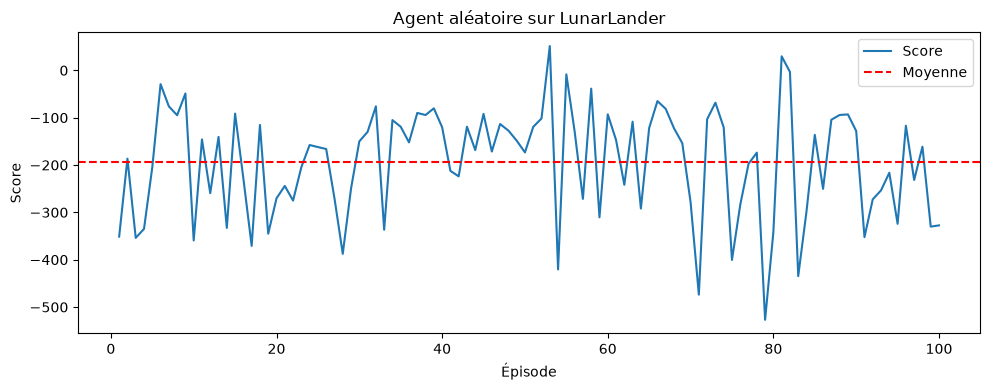

In [5]:
episodes = np.arange(1, len(scores) + 1)

plt.figure(figsize=(10, 4))
plt.plot(episodes, scores, label="Score")
plt.axhline(np.mean(scores), color="red", linestyle="--", label="Moyenne")
plt.xlabel("Épisode")
plt.ylabel("Score")
plt.title("Agent aléatoire sur LunarLander")
plt.legend()
plt.tight_layout()
plt.show()


## Bilan de l'agent aléatoire

Sur ces 100 épisodes, le score moyen est de -193.03, avec un écart-type de 115.39.
On obtient 91 crashs et 9 sorties de l'écran. Le module n'arrive jamais au repos sur cet essai.
L'agent aléatoire donne donc un point de départ, mais ne réussit pas la tâche.

## Réseau DQN

Le réseau reçoit les valeurs de l'état et renvoie une Q-value par action.
Une Q-value estime les récompenses qu'on peut espérer en prenant cette action, puis en continuant à jouer.

On commence avec deux couches de 64 neurones : c'est un petit réseau pour un état de 8 valeurs.
ReLU met les valeurs négatives à zéro entre les couches et permet d'apprendre des relations non linéaires.

La sortie garde une valeur par action. Ces valeurs peuvent être négatives : ce sont des estimations de récompenses, pas des probabilités.

In [6]:
class DQN(nn.Module):
    def __init__(self, state_size, action_size, hidden_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, action_size),
        )

    def forward(self, state):
        return self.network(state)


q_network = DQN(state_size, action_size, HIDDEN_SIZE)
print(q_network)


DQN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
)


## Tester la sortie du réseau

On passe un état du simulateur au réseau sous forme de tenseur float32.
`torch.no_grad()` permet de faire ce test sans préparer de calcul de gradients.
`argmax()` donne l'indice de l'action qui a la plus grande valeur.

Le réseau vient d'être créé : ses poids sont initialisés au hasard. L'action affichée ne vient donc pas encore d'un apprentissage.

In [7]:
state_tensor = torch.tensor(state, dtype=torch.float32)

with torch.no_grad():
    q_values = q_network(state_tensor)

best_action = q_values.argmax().item()

print("Taille de l'entrée :", state_tensor.shape)
print("Taille de la sortie :", q_values.shape)
print("Valeurs des actions :", q_values)
print("Action avec la plus grande valeur :", best_action)


Taille de l'entrée : torch.Size([8])
Taille de la sortie : torch.Size([4])
Valeurs des actions : tensor([ 0.0419,  0.1327,  0.0468, -0.0738])
Action avec la plus grande valeur : 1


## Suite

Le réseau est prêt à recevoir un état et à donner une valeur par action.
Il faudra maintenant ajouter le replay buffer pour garder les expériences du module.
Ensuite, l'apprentissage modifiera les poids du réseau à partir de ces expériences.